# Spectroscopic reference set (part 2)

Real S-PLUS galaxies whose SFH labels come from **Bagpipes fits to their SDSS spectra under exactly the training prior** (`synthetic_model.py`), so they test the ML model on real data with labels it can match. Firefly (SDSS DR16) only selects the galaxies; the fits are validated against the spectra themselves (spectral indices), Halpha SFRs, Gallazzi et al. (2005) ages and metallicities, and scaling relations (section 7).

**Inputs:** `dr3_corrected.csv`, `../Data/sdss_eboss_firefly-dr16.fits`, `literature/` (MPA-JHU and Gallazzi tables), `../dustMaps/csfd/`, `training_set.parquet` (part 1), SDSS spectra (downloaded), S-PLUS Cloud aperture photometry (needs `SPLUS_USERNAME` / `SPLUS_PASSWORD`).
**Outputs:** `spectra/`, `spectral_fits/jobs/` (one `.npz` per fit job), `spectral_fits/` (one `.h5` per finished fit, plus `fit_log.csv` and, for Slurm tasks, `fit_logs/<job_id>.csv`), `spectral_fits/selection.csv` (selected galaxies, append-only), `spectral_fits/failures.csv` (download and prepare failures), `spectral_fits/calibration_mocks.joblib`, `spectroscopic_reference.csv`, `validation_summary.csv`, `validation_indices.png`, `validation_halpha_gallazzi.png`, `validation_relations.png`.
**Run:** top to bottom with the *Inference4ETGs (MultiNest)* kernel, after `training_set.ipynb`. The notebook does not run the fits: it exports one job per galaxy and per calibration mock to `spectral_fits/jobs/`, and `run_spectral_fits.py` fits them outside the notebook (one core per fit, on a many-core PC or a Slurm cluster; set `RUN_FITS_HERE = True` to start it from the notebook). Copy the resulting `.h5` files back into `spectral_fits/` and re-run the analysis cells: they accept zero, some or all fits. The fitter must pass a **calibration test** on mocks drawn from the prior; the verdict is stored as `fitter_calibrated` in the reference CSV.

Spectra fit 3″ (SDSS) or 2″ (BOSS) fibres, so photometry is the 3″ S-PLUS aperture, and BOSS galaxies are reported separately. The **test** half of the split is used once, for the final ML evaluation; with a few tens of galaxies this is a pilot-size set.

In [1]:
import glob
import os
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord, match_coordinates_sky
from astropy.io import fits
from astroquery.sdss import SDSS
from dustmaps.csfd import CSFDQuery
import joblib

import synthetic_model as sm

# Files and folders
SPLUS_FILE = "dr3_corrected.csv"
FIREFLY_FILE = "../Data/sdss_eboss_firefly-dr16.fits"
DUST_MAP_FILE = "../dustMaps/csfd/csfd_ebv.fits"
DUST_MASK_FILE = "../dustMaps/csfd/mask.fits"
TRAINING_FILE = "training_set.parquet"
SPECTRA_DIRECTORY = "spectra"
FITS_DIRECTORY = "spectral_fits"
JOBS_DIRECTORY = "spectral_fits/jobs"                   # exported fit jobs, one .npz each
SUPERSEDED_DIRECTORY = "spectral_fits/superseded"       # results of earlier, replaced runs
FAILURES_FILE = "spectral_fits/failures.csv"
SELECTION_FILE = "spectral_fits/selection.csv"   # selected specobjids, append-only across passes
MOCK_FILE = "spectral_fits/calibration_mocks.joblib"   # calibration mocks and true labels, kept so their fits stay checkable
OLD_MOCK_FILE = "spectral_fits/mocks.joblib"           # the first run's inject-and-recover mocks (superseded)
OUTPUT_FILE = "spectroscopic_reference.csv"
CREDENTIALS_FILE = "../.env"     # git-ignored; holds SPLUS_USERNAME and SPLUS_PASSWORD
APERTURE_CACHE_FILE = "splus_aperture_photometry.csv"   # raw 3" photometry of every S-PLUS x Firefly match

# Sample
MIN_PROB_GALAXY = 0.8
MATCH_RADIUS = 1.5               # [arcsec]
N_REDSHIFT_BINS = 4
N_AGE_BINS = 3
GALAXIES_PER_CELL = 5
N_REAL_GALAXIES = N_REDSHIFT_BINS * N_AGE_BINS * GALAXIES_PER_CELL   # 60
FIBER_DIAMETER = {"26": 3.0, "v5_13_0": 2.0}   # [arcsec] SDSS legacy and BOSS
SQL_CHUNK = 200                  # specobjids per SDSS SQL query

# Fits (run outside the notebook by run_spectral_fits.py; sm.N_CALIBRATION_MOCKS, sm.MAX_ITERATIONS and
# sm.MIN_COVERAGE_95 set the calibration test and the iteration cap)
RUN_FITS_HERE = False            # True: run_spectral_fits.py is started from the notebook, on N_WORKERS cores
N_WORKERS = 4                    # [cores] used when RUN_FITS_HERE is True; fits take hours, so set it for your machine
LIBMULTINEST_DIRECTORY = "../.venv/lib"   # folder with libmultinest, put on LD_LIBRARY_PATH for the fits
SEED = 0

# S-PLUS aperture photometry. DR4 keeps one table per band, each with its own RA/Dec columns
SPLUS_RA_COLUMN = "RA"
SPLUS_DEC_COLUMN = "DEC"
APERTURE_SOURCES = {}
for band in sm.BANDS:
    APERTURE_SOURCES[band] = (f"dr4_dual.dr4_dual_{band.lower()}", f"{band}_aper_3", f"e_{band}_aper_3")
SPLUS_QUERY_TIMEOUT = 600        # [s]
SPLUS_EXECUTION_MODE = "sync"    # small queries; async jobs are capped at 4 concurrent per account
SPLUS_QUERY_ATTEMPTS = 3         # tries per S-PLUS query before giving up (count)
SPLUS_RETRY_WAIT = 30            # [s] wait after the first failed try; doubles after each further one

SSFR_PASSIVE = -11.0             # [log yr^-1] star-forming above, passive below

os.makedirs(SPECTRA_DIRECTORY, exist_ok=True)
os.makedirs(FITS_DIRECTORY, exist_ok=True)
failures = []

Bagpipes: Latex turned off in rcParams, plots may look strange.


## 1. Sample
S-PLUS DR3 galaxies matched to Firefly DR16 spectra within 1.5″, with spectroscopic redshift inside the prior. One spectrum per S-PLUS galaxy (the closest match).

In [2]:
# 1. S-PLUS galaxies
splus = pd.read_csv(SPLUS_FILE)
splus = splus[splus["PROB_GAL"] > MIN_PROB_GALAXY].reset_index(drop=True)

# 2. Firefly galaxies with a redshift inside the prior, in the S-PLUS declination range
FIREFLY_COLUMNS = ["SPECOBJID", "RUN2D", "PLATE", "MJD", "FIBERID", "RA", "DEC", "Z_NOQSO", "CLASS_NOQSO",
                   "Chabrier_MILES_age_massW", "Chabrier_MILES_metallicity_massW", "Chabrier_MILES_total_mass"]
firefly_data = fits.getdata(FIREFLY_FILE, 1)
firefly = {}
for column in FIREFLY_COLUMNS:
    values = np.asarray(firefly_data[column])
    # FITS stores big-endian numbers; pandas needs the machine's native byte order
    firefly[column] = values.astype(values.dtype.newbyteorder("="))
firefly = pd.DataFrame(firefly)
firefly["CLASS_NOQSO"] = firefly["CLASS_NOQSO"].str.strip()
firefly["RUN2D"] = firefly["RUN2D"].str.strip()
is_galaxy = firefly["CLASS_NOQSO"] == "GALAXY"
in_prior = (firefly["Z_NOQSO"] > sm.Z_RANGE[0]) & (firefly["Z_NOQSO"] < sm.Z_RANGE[1])
in_footprint = (firefly["DEC"] > splus["DEC"].min() - 1) & (firefly["DEC"] < splus["DEC"].max() + 1)
firefly = firefly[is_galaxy & in_prior & in_footprint].reset_index(drop=True)
del firefly_data

# 3. Nearest S-PLUS galaxy of each spectrum
spectrum_coordinates = SkyCoord(firefly["RA"].to_numpy() * u.deg, firefly["DEC"].to_numpy() * u.deg)
splus_coordinates = SkyCoord(splus["RA"].to_numpy() * u.deg, splus["DEC"].to_numpy() * u.deg)
nearest_splus, separation, _ = match_coordinates_sky(spectrum_coordinates, splus_coordinates)
firefly["splus_index"] = nearest_splus
firefly["separation"] = separation.arcsec
matched = firefly[firefly["separation"] < MATCH_RADIUS]

# 4. One spectrum per S-PLUS galaxy: the closest
matched = matched.sort_values("separation").drop_duplicates("splus_index").reset_index(drop=True)
# Kept as text: eBOSS specobjids exceed the int64 range
matched["specobjid"] = matched["SPECOBJID"].str.strip()
matched["fiber_diameter"] = matched["RUN2D"].map(FIBER_DIAMETER)
for column in ("Chabrier_MILES_age_massW", "Chabrier_MILES_metallicity_massW", "Chabrier_MILES_total_mass"):
    missing = matched[column] <= sm.FIREFLY_MISSING
    matched.loc[missing, column] = np.nan
print(f"{len(matched)} S-PLUS galaxies with an SDSS/BOSS spectrum; "
      f"{matched['fiber_diameter'].eq(3.0).sum()} SDSS, {matched['fiber_diameter'].eq(2.0).sum()} BOSS")

1362 S-PLUS galaxies with an SDSS/BOSS spectrum; 900 SDSS, 461 BOSS


In [3]:
# 1. Median S/N of each spectrum from the SDSS database
sn_by_id = {}
identifiers = matched["specobjid"].tolist()
for start in range(0, len(identifiers), SQL_CHUNK):
    chunk = identifiers[start:start + SQL_CHUNK]
    id_list = ", ".join(chunk)
    query = ("SELECT CAST(specObjID AS VARCHAR(20)) AS specobjid_text, snMedian "
             f"FROM SpecObjAll WHERE specObjID IN ({id_list})")
    result = SDSS.query_sql(query, data_release=16)
    for row in result:
        sn_by_id[str(row["specobjid_text"]).strip()] = float(row["snMedian"])
matched["sn_median"] = matched["specobjid"].map(sn_by_id)

# 2. Grid of redshift x Firefly age quantile bins; highest S/N first in each cell
candidates = matched.dropna(subset=["Chabrier_MILES_age_massW", "sn_median"]).copy()
candidates["redshift_bin"] = pd.qcut(candidates["Z_NOQSO"], N_REDSHIFT_BINS, labels=False)
candidates["age_bin"] = pd.qcut(candidates["Chabrier_MILES_age_massW"], N_AGE_BINS, labels=False)

chosen = []
for (redshift_bin, age_bin), cell in candidates.groupby(["redshift_bin", "age_bin"]):
    best = cell.sort_values("sn_median", ascending=False).head(GALAXIES_PER_CELL).copy()
    best["rank_in_cell"] = np.arange(len(best))
    chosen.append(best)
# Round-robin order (best of every cell first), so a budget cut never empties a whole cell
picks = pd.concat(chosen, ignore_index=True)
picks = picks.sort_values(["rank_in_cell", "redshift_bin", "age_bin"]).reset_index(drop=True)
print(f"{len(picks)} galaxies picked this pass (target {N_REAL_GALAXIES})")
display(pd.crosstab(picks["redshift_bin"], picks["age_bin"]))

# 3. Selection kept across passes. The stored ids stay, in their stored order (so the first wave and the
# split never change), and this pass's new picks are appended: a later pass can only add galaxies
stored_identifiers = []
if os.path.exists(SELECTION_FILE):
    stored_identifiers = pd.read_csv(SELECTION_FILE, dtype=str)["specobjid"].tolist()
selection_identifiers = list(stored_identifiers)
for specobjid in picks["specobjid"]:
    if specobjid not in selection_identifiers:
        selection_identifiers.append(specobjid)
pd.DataFrame({"specobjid": selection_identifiers}).to_csv(SELECTION_FILE, index=False)

# 4. Reference galaxies: the stored selection plus every galaxy that already has a fit file (calibration, mock and
# pilot fits are not galaxies), so a pass that changes the picks can never drop a fitted or split galaxy
fitted_identifiers = []
for file_name in sorted(os.listdir(FITS_DIRECTORY)):
    if file_name.endswith(".h5") and not file_name.startswith(("calib_", "mock_", "pilot")):
        fitted_identifiers.append(file_name[:-len(".h5")])
reference_identifiers = list(selection_identifiers)
for specobjid in fitted_identifiers:
    if specobjid not in reference_identifiers:
        reference_identifiers.append(specobjid)

available = set(matched["specobjid"])
lost_identifiers = [specobjid for specobjid in reference_identifiers if specobjid not in available]
if lost_identifiers:
    print(f"WARNING: {len(lost_identifiers)} stored galaxies are no longer in the S-PLUS x Firefly match "
          f"and cannot be rebuilt: {lost_identifiers}")
reference_identifiers = [specobjid for specobjid in reference_identifiers if specobjid in available]
selected = matched.set_index("specobjid").loc[reference_identifiers].reset_index()
selected = selected.rename(columns={"RA": "ra", "DEC": "dec", "Z_NOQSO": "z", "PLATE": "plate", "MJD": "mjd",
                                    "FIBERID": "fiberid", "Chabrier_MILES_age_massW": "firefly_age",
                                    "Chabrier_MILES_metallicity_massW": "firefly_metallicity",
                                    "Chabrier_MILES_total_mass": "firefly_mass"})
print(f"{len(selected)} reference galaxies: {len(stored_identifiers)} stored, "
      f"{len(selection_identifiers) - len(stored_identifiers)} newly picked, "
      f"{len(fitted_identifiers)} with a fit file")

60 galaxies picked this pass (target 60)


age_bin,0,1,2
redshift_bin,,,
0,5,5,5
1,5,5,5
2,5,5,5
3,5,5,5


60 reference galaxies: 60 stored, 0 newly picked, 60 with a fit file


## 2. Spectra
SDSS spectra are **not** corrected for Galactic extinction, so each is dereddened with the same map and law as the S-PLUS photometry (CSFD, CCM89, $R_V = 3.1$), converted to air wavelengths (the models' frame), masked (bad pixels, 5577/6300 Å sky lines) and rebinned to 5 Å.

In [4]:
dust_map = CSFDQuery(map_fname=DUST_MAP_FILE, mask_fname=DUST_MASK_FILE)
galaxy_coordinates = SkyCoord(selected["ra"].to_numpy() * u.deg, selected["dec"].to_numpy() * u.deg)
# The map is a big-endian FITS image; float64 is native, which pandas needs
selected["ebv"] = dust_map(galaxy_coordinates).astype(float)

prepared_spectra = {}
for row in selected.itertuples():
    spectrum_file = os.path.join(SPECTRA_DIRECTORY, f"{row.specobjid}.fits")

    # 1. Download once
    if not os.path.exists(spectrum_file):
        try:
            downloaded = SDSS.get_spectra(plate=int(row.plate), mjd=int(row.mjd), fiberID=int(row.fiberid),
                                          data_release=16)
            downloaded[0].writeto(spectrum_file)
        except Exception as error:
            failures.append({"job_id": str(row.specobjid), "stage": "download", "error": repr(error)})
            continue

    # 2. Prepare for the fit
    with fits.open(spectrum_file) as spectrum_hdus:
        table = spectrum_hdus[1].data
        wavelength_vacuum = 10 ** table["loglam"].astype(float)
        flux = table["flux"].astype(float)
        ivar = table["ivar"].astype(float)
    try:
        prepared_spectra[row.specobjid] = sm.prepare_spectrum(wavelength_vacuum, flux, ivar, row.ebv)
    except ValueError as error:
        failures.append({"job_id": str(row.specobjid), "stage": "prepare", "error": repr(error)})

print(f"{len(prepared_spectra)} spectra ready; {len(failures)} failures so far")

60 spectra ready; 0 failures so far


## 3. Aperture photometry
3″-diameter S-PLUS magnitudes, matching the SDSS fibre, dereddened like `dr3_corrected.csv`. They set the mass normalisation of the labels and feed the coverage test; they never enter the spectral fit.

The raw (not dereddened) magnitudes of every S-PLUS x Firefly match are cached in `splus_aperture_photometry.csv`; the S-PLUS Cloud is queried only for selected galaxies missing from that cache (each query is retried up to `SPLUS_QUERY_ATTEMPTS` times), and every newly queried galaxy is appended to the cache, so a re-run needs no live queries.

In [5]:
# Output column names, built once
aperture_columns = []
aperture_error_columns = []
for band in sm.BANDS:
    aperture_columns.append(f"{band}_aper")
    aperture_error_columns.append(f"e_{band}_aper")

# Columns of the cache file, in file order
cache_columns = ["specobjid", "ra", "dec", "splus_ra", "splus_dec", "match_separation_arcsec"]
for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
    cache_columns.append(magnitude_column)
    cache_columns.append(error_column)


def query_to_dataframe(result):
    """S-PLUS Cloud query result as a DataFrame.

    Inputs: result: what splusdata's Core.query returns, an astropy Table or a DataFrame.
    Returns: pandas DataFrame with the same rows and columns.
    """
    if hasattr(result, "to_pandas"):
        return result.to_pandas()
    return pd.DataFrame(result)


def cone_query(table, columns, ra, dec, radius_arcsec):
    """ADQL selecting columns of every object within radius of one position.

    One position per query: the S-PLUS Cloud rejects several OR-ed cones with "Column 'ra' does not exist".
    Inputs: table: S-PLUS Cloud table name (str); columns: names of the columns to select besides the
            position (list of str); ra, dec: cone centre [deg]; radius_arcsec: cone radius [arcsec].
    Returns: the ADQL query text (str).
    """
    radius_degrees = radius_arcsec / 3600
    column_list = ", ".join([SPLUS_RA_COLUMN, SPLUS_DEC_COLUMN, *columns])
    return (f"SELECT {column_list} FROM {table} WHERE 1 = CONTAINS(POINT('ICRS', {SPLUS_RA_COLUMN}, "
            f"{SPLUS_DEC_COLUMN}), CIRCLE('ICRS', {ra}, {dec}, {radius_degrees}))")


def run_query_with_retries(connection, query):
    """Run one S-PLUS Cloud query, trying again after a failure (the server is slow and sometimes drops requests).

    Waits SPLUS_RETRY_WAIT seconds after the first failure and twice as long after each further one.
    Inputs: connection: logged-in splusdata.Core; query: ADQL text (str).
    Returns: DataFrame with the query result (empty if no object was found).
    Raises: the last error if all SPLUS_QUERY_ATTEMPTS tries fail.
    """
    wait = SPLUS_RETRY_WAIT
    for attempt in range(1, SPLUS_QUERY_ATTEMPTS + 1):
        try:
            return query_to_dataframe(connection.query(query, execution_mode=SPLUS_EXECUTION_MODE,
                                                       timeout=SPLUS_QUERY_TIMEOUT))
        except Exception as error:
            if attempt == SPLUS_QUERY_ATTEMPTS:
                raise
            print(f"S-PLUS query failed (try {attempt} of {SPLUS_QUERY_ATTEMPTS}): {error!r}; "
                  f"trying again in {wait} s")
            time.sleep(wait)
            wait = 2 * wait


def query_one_galaxy(connection, specobjid, ra, dec):
    """Raw 3" aperture photometry of one galaxy, as one row of the cache file.

    Each band is a separate table, so there is one query per band; in each, the closest object within
    MATCH_RADIUS is taken. splus_ra, splus_dec and match_separation_arcsec describe the closest object of
    the first band in which one was found.
    Inputs: connection: logged-in splusdata.Core; specobjid: SDSS identifier (str); ra, dec: SDSS position [deg].
    Returns: dict with the cache_columns (magnitudes [mag] and errors [mag] are NaN where nothing was found).
    """
    row = dict.fromkeys(cache_columns, np.nan)
    row.update(specobjid=specobjid, ra=ra, dec=dec)
    galaxy_position = SkyCoord(ra * u.deg, dec * u.deg)
    for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
        query = cone_query(table, [magnitude_column, error_column], ra, dec, MATCH_RADIUS)
        result = run_query_with_retries(connection, query)
        if len(result) == 0:
            continue
        result_positions = SkyCoord(result[SPLUS_RA_COLUMN].to_numpy() * u.deg,
                                    result[SPLUS_DEC_COLUMN].to_numpy() * u.deg)
        separations = result_positions.separation(galaxy_position).arcsec
        closest = np.argmin(separations)
        row[magnitude_column] = result[magnitude_column].iloc[closest]
        row[error_column] = result[error_column].iloc[closest]
        if np.isnan(row["splus_ra"]):
            row["splus_ra"] = result[SPLUS_RA_COLUMN].iloc[closest]
            row["splus_dec"] = result[SPLUS_DEC_COLUMN].iloc[closest]
            row["match_separation_arcsec"] = separations[closest]
    return row


def query_aperture_photometry(galaxies):
    """Raw 3" aperture magnitudes and errors of galaxies from the S-PLUS Cloud, saved to the cache as they arrive.

    Each galaxy is appended to APERTURE_CACHE_FILE as soon as it is queried (a galaxy with no S-PLUS object
    is stored as NaN), so an interrupted run loses nothing.
    Inputs: galaxies: DataFrame with columns specobjid (str), ra and dec [deg].
    Returns: DataFrame indexed like galaxies, with {band}_aper and e_{band}_aper columns [mag] (NaN if not found).
    """
    import splusdata
    from dotenv import load_dotenv

    load_dotenv(CREDENTIALS_FILE)
    connection = splusdata.Core(os.environ["SPLUS_USERNAME"], os.environ["SPLUS_PASSWORD"])

    photometry = pd.DataFrame(np.nan, index=galaxies.index, columns=aperture_columns + aperture_error_columns)
    for galaxy in galaxies.itertuples():
        row = query_one_galaxy(connection, galaxy.specobjid, galaxy.ra, galaxy.dec)
        write_header = not os.path.exists(APERTURE_CACHE_FILE)
        pd.DataFrame([row], columns=cache_columns).to_csv(APERTURE_CACHE_FILE, mode="a", header=write_header,
                                                          index=False)
        for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
            photometry.loc[galaxy.Index, f"{band}_aper"] = row[magnitude_column]
            photometry.loc[galaxy.Index, f"e_{band}_aper"] = row[error_column]
    return photometry


# 1. Raw magnitudes from the cache, by specobjid
for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
    selected[f"{band}_aper"] = np.nan
    selected[f"e_{band}_aper"] = np.nan
in_cache = pd.Series(False, index=selected.index)
if os.path.exists(APERTURE_CACHE_FILE):
    cache = pd.read_csv(APERTURE_CACHE_FILE, dtype={"specobjid": str})
    cache = cache.drop_duplicates("specobjid").set_index("specobjid")
    in_cache = selected["specobjid"].isin(cache.index)
    cached = cache.loc[selected.loc[in_cache, "specobjid"]]
    for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
        selected.loc[in_cache, f"{band}_aper"] = cached[magnitude_column].to_numpy()
        selected.loc[in_cache, f"e_{band}_aper"] = cached[error_column].to_numpy()
print(f"{in_cache.sum()} of {len(selected)} galaxies found in {APERTURE_CACHE_FILE}")

# 2. The rest from the S-PLUS Cloud (appended to the cache as they arrive)
if not in_cache.all():
    queried = query_aperture_photometry(selected[~in_cache])
    selected.loc[queried.index, queried.columns] = queried

# 3. Galactic extinction, as for dr3_corrected.csv (non-detections keep their 99)
raw_magnitudes = selected[aperture_columns].to_numpy()
dereddened = sm.deredden_magnitudes(raw_magnitudes, selected["ebv"].to_numpy())
measured = raw_magnitudes < sm.UNDETECTED_MAGNITUDE
selected[aperture_columns] = np.where(measured, dereddened, raw_magnitudes)

missing_photometry = selected["r_aper"].isna()
print(f"Aperture photometry found for {(~missing_photometry).sum()} of {len(selected)} galaxies")
assert (~missing_photometry).sum() >= 0.9 * len(selected), "Aperture photometry missing for >10% of galaxies"

60 of 60 galaxies found in splus_aperture_photometry.csv
Aperture photometry found for 60 of 60 galaxies


## 4. Fits (outside the notebook)
MultiNest fits of real galaxies need hours each, so they run outside the notebook: this section writes one job file per fit to `spectral_fits/jobs/` and `run_spectral_fits.py` runs them, one single-core process per fit (see its docstring for the environment and the Slurm example `slurm_fit.sh`). Finished fits are `spectral_fits/<job_id>.h5`; copy them back and re-run from the calibration test on.

**Jobs:** every selected galaxy, plus `sm.N_CALIBRATION_MOCKS` calibration mocks drawn from the full training prior (`sfh_type` included), each with the wavelengths, mask and errors of a random selected galaxy. The mocks and their true labels are stored in `MOCK_FILE` and reused, so their fits stay checkable. Results of the first run (fits with a lower iteration cap than `sm.MAX_ITERATIONS`, and its mock fits) are first moved to `spectral_fits/superseded/`.

In [6]:
def move_to_superseded(name):
    """Move a file or folder of FITS_DIRECTORY into SUPERSEDED_DIRECTORY, unless that name is already there.

    Inputs: name: file or folder name inside FITS_DIRECTORY (str).
    Returns: True if it was moved, False if it does not exist or the destination is taken (bool).
    """
    source = os.path.join(FITS_DIRECTORY, name)
    destination = os.path.join(SUPERSEDED_DIRECTORY, name)
    if not os.path.exists(source):
        return False
    if os.path.exists(destination):
        print(f"WARNING: {destination} already exists; {source} was left where it is")
        return False
    os.makedirs(SUPERSEDED_DIRECTORY, exist_ok=True)
    shutil.move(source, destination)
    return True


# 1. The first run's mock fits and their folders (names mock_<k>)
moved = []
for name in sorted(os.listdir(FITS_DIRECTORY)):
    if name.startswith("mock_") and move_to_superseded(name):
        moved.append(name)

# 2. Fits stored with a lower iteration cap than sm.MAX_ITERATIONS (or none), with their MultiNest folders.
# An unreadable file stays: the external run fits that job again
for name in sorted(os.listdir(FITS_DIRECTORY)):
    if not name.endswith(".h5"):
        continue
    try:
        _, metadata = sm.load_fit(os.path.join(FITS_DIRECTORY, name))
    except Exception:
        continue
    if metadata.get("max_iterations", 0) < sm.MAX_ITERATIONS:
        for moved_name in (name, name[:-len(".h5")]):
            if move_to_superseded(moved_name):
                moved.append(moved_name)

# 3. The first run's mock file; the calibration mocks are drawn afresh into MOCK_FILE
old_mock_name = os.path.basename(OLD_MOCK_FILE)
if move_to_superseded(old_mock_name):
    moved.append(old_mock_name)

print(f"Moved {len(moved)} items to {SUPERSEDED_DIRECTORY}: {moved}" if moved
      else f"Nothing to supersede: no earlier fit has a lower iteration cap than {sm.MAX_ITERATIONS}")

Nothing to supersede: no earlier fit has a lower iteration cap than 50000


In [7]:
def real_galaxy_job(specobjid):
    """Fit job of one selected galaxy.

    Inputs: specobjid: SDSS identifier (str) of a galaxy in selected with a prepared spectrum.
    Returns: dict with job_id (str), spectrum (dict from prepare_spectrum: wavelength [Angstrom], flux, ivar)
             and redshift (spectroscopic, dimensionless).
    """
    redshift = float(selected.loc[selected["specobjid"] == specobjid, "z"].iloc[0])
    return {"job_id": str(specobjid), "spectrum": prepared_spectra[specobjid], "redshift": redshift}


real_jobs = [real_galaxy_job(specobjid) for specobjid in prepared_spectra]
assert len(real_jobs) > 0, "No spectrum was prepared; there is nothing to fit"

# Calibration mocks: drawn once and stored with their true labels, because their fits are cached on disk and
# must be compared with the mocks they were made from. Delete MOCK_FILE (and the calib_* fits) to draw new ones
if os.path.exists(MOCK_FILE):
    calibration_jobs, calibration_truths = joblib.load(MOCK_FILE)
    print(f"Reusing {len(calibration_jobs)} stored calibration mocks from {MOCK_FILE}")
else:
    templates = [(job["spectrum"], job["redshift"]) for job in real_jobs]
    calibration_jobs, calibration_truths = sm.draw_calibration_mocks(
        sm.N_CALIBRATION_MOCKS, templates, np.random.default_rng(SEED))
    joblib.dump((calibration_jobs, calibration_truths), MOCK_FILE)
    print(f"Drew {len(calibration_jobs)} calibration mocks from the training prior, stored in {MOCK_FILE}")

Reusing 33 stored calibration mocks from spectral_fits/calibration_mocks.joblib


In [8]:
# 1. One job file per calibration mock and per selected galaxy
for job in [*calibration_jobs, *real_jobs]:
    sm.export_job(job, JOBS_DIRECTORY)
pd.DataFrame(failures).to_csv(FAILURES_FILE, index=False)
n_jobs = len(calibration_jobs) + len(real_jobs)
print(f"Exported {len(calibration_jobs)} calibration mocks and {len(real_jobs)} galaxies to {JOBS_DIRECTORY}/ "
      f"({len(failures)} download or prepare failures in {FAILURES_FILE})")

# 2. How to run them
run_command = f"python run_spectral_fits.py --jobs-dir {JOBS_DIRECTORY} --output-dir {FITS_DIRECTORY}"
print("\nOn a many-core PC, one fit per core (--workers defaults to the usable cores minus one):")
print(f"  LD_LIBRARY_PATH={LIBMULTINEST_DIRECTORY} {run_command} --workers <N>")
print(f"On a Slurm cluster: copy the bundle (see run_spectral_fits.py), set --array=0-{n_jobs - 1} in slurm_fit.sh, "
      "then  sbatch slurm_fit.sh")
print(f"Progress at any time:\n  LD_LIBRARY_PATH={LIBMULTINEST_DIRECTORY} {run_command} --status")
print(f"Then copy the <job_id>.h5 files back into {FITS_DIRECTORY}/ and re-run from the calibration test.")

# 3. Optional: run the fits here. The output is passed on line by line, so progress shows in the notebook
if RUN_FITS_HERE:
    print(f"\nRunning the fits here on {N_WORKERS} workers; interrupt the kernel to stop (finished fits are kept)")
    environment = dict(os.environ, LD_LIBRARY_PATH=LIBMULTINEST_DIRECTORY)
    process = subprocess.Popen([sys.executable, "run_spectral_fits.py", "--jobs-dir", JOBS_DIRECTORY,
                                "--output-dir", FITS_DIRECTORY, "--workers", str(N_WORKERS)],
                               env=environment, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    try:
        for line in process.stdout:
            print(line, end="")
    finally:
        process.terminate()
        process.wait()
    assert process.returncode == 0, "run_spectral_fits.py failed; see its output above"

Exported 33 calibration mocks and 60 galaxies to spectral_fits/jobs/ (0 download or prepare failures in spectral_fits/failures.csv)

On a many-core PC, one fit per core (--workers defaults to the usable cores minus one):
  LD_LIBRARY_PATH=../.venv/lib python run_spectral_fits.py --jobs-dir spectral_fits/jobs --output-dir spectral_fits --workers <N>
On a Slurm cluster: copy the bundle (see run_spectral_fits.py), set --array=0-92 in slurm_fit.sh, then  sbatch slurm_fit.sh
Progress at any time:
  LD_LIBRARY_PATH=../.venv/lib python run_spectral_fits.py --jobs-dir spectral_fits/jobs --output-dir spectral_fits --status
Then copy the <job_id>.h5 files back into spectral_fits/ and re-run from the calibration test.


## 5. Calibration test
Each calibration mock has known labels. The fitter is **calibrated** when, for `mw_age`, `Z_fin` and `f_old`, at least `sm.MIN_COVERAGE_95` (85%) of the true values lie inside the 95% interval of their posterior. The 68% coverage is reported too. The verdict goes into every row of the reference CSV as `fitter_calibrated` (empty until all mocks are fitted); it does not stop the notebook. A failure is a finding about the prior or the model, not a crash.

In [9]:
def converged_from_multinest(job_id, metadata):
    """Whether a fit certainly stopped before its iteration limit, judged from its MultiNest folder.

    Uses the upper bound of the outer-loop iteration count (sm.multinest_iteration_bounds), so a capped
    run is never called converged. The limit is the one stored in the fit's metadata. A fit saved before
    the limit was stored (or without its MultiNest folder) keeps the flag stored when it ran: that flag
    came from the ev.dat row count, which overcounts iterations, so a stored True is already safe and a
    stored False is never upgraded against a limit that may differ from the one the fit used.
    Inputs: job_id: fit identifier, the name of its .h5 file and MultiNest folder (str); metadata: dict from sm.load_fit.
    Returns: True if the run converged, else False (bool).
    """
    iteration_limit = metadata.get("max_iterations")
    multinest_basename = os.path.join(FITS_DIRECTORY, job_id) + "/"
    if iteration_limit is None or not os.path.exists(multinest_basename + "ev.dat"):
        return bool(metadata["converged"])
    return sm.multinest_iteration_bounds(multinest_basename)[1] < iteration_limit


# 1. Posteriors of the calibration mocks that have finished
calibration_posteriors = {}
calibration_converged = 0
for job_id in calibration_truths:
    fit_file = os.path.join(FITS_DIRECTORY, f"{job_id}.h5")
    if os.path.exists(fit_file):
        calibration_posteriors[job_id], metadata = sm.load_fit(fit_file)
        calibration_converged += int(converged_from_multinest(job_id, metadata))

# 2. Coverage per label and interval
n_finished = len(calibration_posteriors)
n_expected = len(calibration_truths)
calibration_table = sm.calibration_coverage(calibration_posteriors, calibration_truths, sm.CALIBRATION_LABELS)
display(calibration_table.pivot(index="label", columns="level", values=["coverage", "n_jobs"]).round(2))

# 3. Verdict: only a complete set of mocks decides
coverage_95 = calibration_table[calibration_table["level"] == 0.95].set_index("label")["coverage"]
if n_finished < n_expected:
    fitter_calibrated = pd.NA
    print(f"INCOMPLETE: {n_finished} of {n_expected} calibration mocks fitted ({calibration_converged} converged); "
          "fitter_calibrated stays empty until all are done")
else:
    fitter_calibrated = bool((coverage_95 >= sm.MIN_COVERAGE_95).all())
    verdict = "PASS" if fitter_calibrated else "FAIL"
    print(f"{verdict}: 95% coverage {coverage_95.round(2).to_dict()} against the required {sm.MIN_COVERAGE_95} "
          f"({n_finished} mocks, {calibration_converged} converged)")

coverage       n_jobs      
level      0.68  0.95   0.68  0.95
label                             
Z_fin      0.48  0.93   27.0  27.0
f_old      0.59  0.96   27.0  27.0
mw_age     0.67  1.00   27.0  27.0

INCOMPLETE: 27 of 33 calibration mocks fitted (27 converged); fitter_calibrated stays empty until all are done


## 6. Labels, coverage and split
Each posterior sample's mass-like labels are rescaled by its aperture $r$ offset ($-0.4\,\Delta m$ dex), then summarised as 16/50/84th percentiles. Coverage uses the aperture photometry at the spectroscopic redshift. The table has every galaxy of the stored selection (`selection.csv`) and every galaxy with a fit file, so a later pass never drops one. Fits may be missing, partly or entirely: the cells below run with whatever exists and print the counts. `converged` is recomputed from each fit's MultiNest folder (`sm.multinest_iterations` below the iteration limit), because the stored flag of older fits counted one ev.dat row per mode and iteration. Galaxies that converged and are covered go to `validation` or `test` by a hash of `specobjid`. Read the output with `dtype={"specobjid": str}` (eBOSS ids exceed int64).

In [10]:
LABEL_COLUMNS = ["log_ssfr", "mw_metallicity", "veldisp", "noise_scale", "Z_fin", "Av_ism",
                 *sm.SUMMARY_LABEL_COLUMNS, *sm.BIN_LABEL_COLUMNS]

# 1. Posterior summaries per galaxy (selected holds the stored selection and every fitted galaxy, see cell 4)
failed_identifiers = {failure["job_id"] for failure in failures}   # stage prepare or download
# run_spectral_fits.py writes fit_log.csv (local runs) and fit_logs/<job_id>.csv (one per Slurm task). A line cut
# short by a copy is skipped, a repeated header row is dropped, an empty or unparseable file is ignored with a warning
task_logs = sorted(glob.glob(os.path.join(FITS_DIRECTORY, "fit_logs", "*.csv")))
log_files = [os.path.join(FITS_DIRECTORY, "fit_log.csv"), *task_logs]
log_tables = []
for log_file in log_files:
    if os.path.exists(log_file):
        try:
            log_tables.append(pd.read_csv(log_file, dtype=str, on_bad_lines="skip"))
        except (pd.errors.EmptyDataError, pd.errors.ParserError) as log_error:
            print(f"WARNING: {log_file} ignored ({log_error})")
fit_log = pd.concat(log_tables, ignore_index=True) if log_tables else pd.DataFrame(columns=["job_id", "status"])
if {"job_id", "status"} <= set(fit_log.columns):
    fit_log = fit_log[fit_log["job_id"] != "job_id"]
    failed_identifiers |= set(fit_log.loc[fit_log["status"] == "failed", "job_id"])
rows = []
for galaxy in selected.itertuples():
    fit_file = os.path.join(FITS_DIRECTORY, f"{galaxy.specobjid}.h5")
    row = {"specobjid": galaxy.specobjid}
    if not os.path.exists(fit_file):
        # Failed galaxies are told apart from those the budget left for a later pass
        row["fit_status"] = "failed" if galaxy.specobjid in failed_identifiers else "not_fitted"
        rows.append(row)
        continue
    posterior, metadata = sm.load_fit(fit_file)

    # Mass-like labels follow the aperture r magnitude: log X = log X_model - 0.4 (r_obs - r_model)
    offsets = galaxy.r_aper - posterior["model_r"]
    posterior = sm.rescale_mass_labels(posterior, offsets)
    posterior["log_ssfr"] = posterior["log_sfr"] - posterior["log_mstar"]   # normalisation-free

    row["fit_status"] = "fitted"
    row["converged"] = converged_from_multinest(galaxy.specobjid, metadata)
    row["fit_hours"] = metadata["run_time"] / 3600
    row.update(sm.summarise_posterior(posterior, LABEL_COLUMNS))
    rows.append(row)
reference = selected.merge(pd.DataFrame(rows), on="specobjid", how="left")
# With no fit yet (or only some) the summary columns may be missing: add them empty, so later steps run
empty_summary = pd.DataFrame(np.zeros((1, len(LABEL_COLUMNS))), columns=LABEL_COLUMNS)
expected_columns = ["converged", "fit_hours", *sm.summarise_posterior(empty_summary, LABEL_COLUMNS)]
missing_columns = [column for column in expected_columns if column not in reference.columns]
reference = reference.reindex(columns=[*reference.columns, *missing_columns])

# 2. Galaxy type and fibre labels
fitted = reference["fit_status"] == "fitted"
reference["galaxy_type"] = np.where(reference["log_ssfr_median"] > SSFR_PASSIVE, "star-forming", "passive")
reference["fibre"] = reference["fiber_diameter"].map({3.0: "SDSS 3\"", 2.0: "BOSS 2\""})

# 3. Coverage of the aperture photometry at the spectroscopic redshift
training = pd.read_parquet(TRAINING_FILE, columns=["redshift", *sm.BANDS])
aperture_magnitudes = reference[aperture_columns].to_numpy()
aperture_errors = reference[aperture_error_columns].to_numpy()
aperture_detected = sm.detected_bands(aperture_magnitudes, aperture_errors)
coverage = sm.coverage_test(aperture_magnitudes, aperture_errors, aperture_detected,
                            reference["z"].to_numpy(), np.full(len(reference), sm.DZ_MIN),
                            training[sm.BANDS].to_numpy(), training["redshift"].to_numpy())
for column in coverage.columns:
    reference[column] = coverage[column].to_numpy()

# 4. Locked split
# Validation results (section 7) are reported, never used as a filter
usable = reference["converged"].eq(True) & reference["covered"].astype(bool)
reference["split"] = "excluded"
for row_index in np.flatnonzero(usable.to_numpy()):
    reference.loc[row_index, "split"] = sm.split_by_hash(reference.loc[row_index, "specobjid"])

## 7. Validation of the spectral fits
Three layers, all report-only (no galaxy is filtered; the split stays "converged and covered"). **Layer 1:** observed spectral indices (D4000$_n$, H$\delta_A$, Mgb, Fe5270, Fe5335, [MgFe]') against the posterior-predictive indices of each fit, for every fitted galaxy. **Layer 2:** MPA-JHU H$\alpha$ SFRs (BPT star-forming SDSS galaxies) and Gallazzi et al. (2005) r-band light-weighted ages and metallicities (SDSS galaxies in their catalogue); BOSS galaxies are "not available". **Layer 3:** our galaxies against the Gallazzi mass-metallicity relation, the Speagle et al. (2014) main sequence and the age-$\sigma$ relation of passive galaxies, as the fraction inside the 16-84th percentile bands.
Caveat for the $|z|$ fractions: $\sigma_{obs}$ comes from the raw SDSS `ivar`, while the fit scaled its errors by `noise_scale` (1-5), and `veldisp` is weakly constrained at the fit's 5 Å binning, so $|z|$ may be inflated for the $\sigma$-sensitive Mg/Fe indices.

In [11]:
import h5py

import spectral_validation as sv

LITERATURE_DIRECTORY = "literature"
VALIDATION_SUMMARY_FILE = "validation_summary.csv"
INDEX_FIGURE_FILE = "validation_indices.png"
TRACER_FIGURE_FILE = "validation_halpha_gallazzi.png"
RELATION_FIGURE_FILE = "validation_relations.png"
VALIDATION_SEED = 11


def load_unit_cube_samples(path):
    """Equal-weight unit-cube posterior samples stored by sm.save_fit (dataset 'unit_cube_samples')."""
    with h5py.File(path, "r") as source:
        return source["unit_cube_samples"][()]


# Layer 1: observed indices vs posterior-predictive model indices, galaxy by galaxy
rng = np.random.default_rng(VALIDATION_SEED)
index_rows = []
for galaxy in reference[fitted].itertuples():
    rest_wavelength, flux, ivar = sv.rest_frame_spectrum(os.path.join(SPECTRA_DIRECTORY, f"{galaxy.specobjid}.fits"),
                                                         galaxy.z, galaxy.ebv)
    measured = sv.measure_indices(rest_wavelength, flux, ivar, rng)
    observed_air = rest_wavelength * (1 + galaxy.z)
    in_fit_range = (observed_air >= sm.OBSERVED_RANGE[0]) & (observed_air <= sm.OBSERVED_RANGE[1])
    posterior_cubes = load_unit_cube_samples(os.path.join(FITS_DIRECTORY, f"{galaxy.specobjid}.h5"))
    predictive = sv.predictive_indices(posterior_cubes, galaxy.z, observed_air[in_fit_range],
                                       flux[in_fit_range], ivar[in_fit_range])
    row = {"specobjid": galaxy.specobjid}
    for name in sv.INDEX_NAMES:
        row[f"{name}_obs"] = measured[name]
        row[f"{name}_obs_err"] = measured[f"{name}_err"]
    row.update(sv.index_comparison(measured, predictive))
    index_rows.append(row)
reference = reference.merge(pd.DataFrame(index_rows), on="specobjid", how="left")

In [12]:
# Layer 2a: MPA-JHU indices (cross-check of our index code), Halpha SFR, velocity dispersion
mpa = pd.read_csv(os.path.join(LITERATURE_DIRECTORY, "mpa_jhu_reference.csv"), dtype={"specobjid": str})
mpa = mpa.add_prefix("mpa_").rename(columns={"mpa_specobjid": "specobjid"})
reference = reference.merge(mpa, on="specobjid", how="left")
STAR_FORMING_BPT_CLASS = 1      # MPA-JHU BPT class 1 = star-forming
FIBRE_YOUNG_BIN = "logsfr_bin_00_median"   # Bagpipes SFR over 0-14 Myr, the time scale Halpha traces
reference["bagpipes_log_sfr_young"] = reference[FIBRE_YOUNG_BIN]
reference["delta_log_sfr_halpha"] = (reference["bagpipes_log_sfr_young"]
                                     - (reference["mpa_sfr_fib_p50"]))   # both Kroupa: no IMF offset (ruling Q6)
halpha_usable = reference["mpa_bptclass"].eq(STAR_FORMING_BPT_CLASS) & reference["delta_log_sfr_halpha"].notna()

# Layer 2b: Gallazzi et al. (2005) light-weighted ages and metallicities
gallazzi = pd.read_csv(os.path.join(LITERATURE_DIRECTORY, "gallazzi_reference.csv"), dtype={"specobjid": str})
light_rows = []
for galaxy in reference[fitted].itertuples():
    samples = load_unit_cube_samples(os.path.join(FITS_DIRECTORY, f"{galaxy.specobjid}.h5"))
    light = sv.light_weighted_age_and_metallicity(samples, galaxy.z)
    row = {"specobjid": galaxy.specobjid}
    for column in ("log_age_light", "log_metallicity_light"):
        low, middle, high = np.percentile(light[column], [16, 50, 84])
        row[f"{column}_p16"], row[f"{column}_median"], row[f"{column}_p84"] = low, middle, high
    light_rows.append(row)
reference = reference.merge(pd.DataFrame(light_rows), on="specobjid", how="left")
reference = reference.merge(gallazzi, on="specobjid", how="left")
reference["delta_log_age_gallazzi"] = reference["log_age_light_median"] - reference["gallazzi_log_age_p50"]
reference["delta_log_z_gallazzi"] = reference["log_metallicity_light_median"] - reference["gallazzi_log_z_p50"]

In [13]:
# Layer 3: our galaxies on literature scaling relations. Relations use total masses: the 3" aperture mass is
# scaled to the total S-PLUS r magnitude assuming a constant mass-to-light ratio across the galaxy
splus_catalogue = pd.read_csv(SPLUS_FILE, usecols=["r_auto"])
reference["r_auto"] = splus_catalogue["r_auto"].to_numpy()[reference["splus_index"].astype(int)]
aperture_to_total = -sm.DEX_PER_MAGNITUDE * (reference["r_auto"] - reference["r_aper"])
reference["log_mstar_total"] = reference["log_mstar_median"] + aperture_to_total
reference["log_sfr_total"] = reference["log_sfr_median"] + aperture_to_total
star_forming = reference["galaxy_type"].eq("star-forming")
passive = reference["galaxy_type"].eq("passive")

relations_directory = os.path.join(LITERATURE_DIRECTORY, "relations")
mass_metallicity_band = pd.read_csv(os.path.join(relations_directory, "mass_metallicity.csv"))
age_sigma_band = pd.read_csv(os.path.join(relations_directory, "age_sigma_passive.csv"))

reference["in_mass_metallicity_band"] = sv.inside_band(reference["log_mstar_total"].to_numpy(),
                                                       reference["log_metallicity_light_median"].to_numpy(),
                                                       mass_metallicity_band) if len(mass_metallicity_band) else pd.NA
main_sequence = sv.speagle_main_sequence(reference["log_mstar_total"].to_numpy(), reference["z"].to_numpy())
offset_from_sequence = reference["log_sfr_total"].to_numpy() - main_sequence
on_sequence = np.abs(offset_from_sequence) <= sv.SPEAGLE_SCATTER
reference["in_main_sequence_band"] = pd.array(np.where(star_forming, on_sequence, pd.NA), dtype="boolean")
log_sigma = np.log10(reference["mpa_velDisp"].to_numpy(dtype=float))
age_sigma_flags = sv.inside_band(log_sigma, reference["log_age_light_median"].to_numpy(), age_sigma_band) \
    if len(age_sigma_band) else pd.array([pd.NA] * len(reference), dtype="boolean")
reference["in_age_sigma_band"] = pd.array(np.where(passive, age_sigma_flags, pd.NA), dtype="boolean")

,layer,quantity,group,n,available,fraction_abs_z_below_2,median_z,z_scatter,median_offset,scatter,fraction_inside_band
0,1 indices,D4000_n,all,59,True,0.797,0.101,1.674,NaN,NaN,NaN
1,1 indices,Hdelta_A,all,60,True,0.867,0.124,1.334,NaN,NaN,NaN
2,1 indices,Mgb,all,60,True,0.567,1.698,1.508,NaN,NaN,NaN
3,1 indices,Fe5270,all,60,True,0.933,-0.332,0.932,NaN,NaN,NaN
4,1 indices,Fe5335,all,60,True,0.933,-0.050,1.049,NaN,NaN,NaN
5,1 indices,MgFe_prime,all,60,True,0.817,0.807,1.343,NaN,NaN,NaN
6,2 tracers,Halpha SFR,all,4,True,NaN,NaN,NaN,-0.382,0.413,NaN
7,2 tracers,Gallazzi age,all,42,True,NaN,NaN,NaN,-0.125,0.124,NaN
8,2 tracers,Gallazzi metallicity,all,42,True,NaN,NaN,NaN,0.050,0.168,NaN
9,3 relations,mass-metallicity,all,55,True,NaN,NaN,NaN,NaN,NaN,0.400


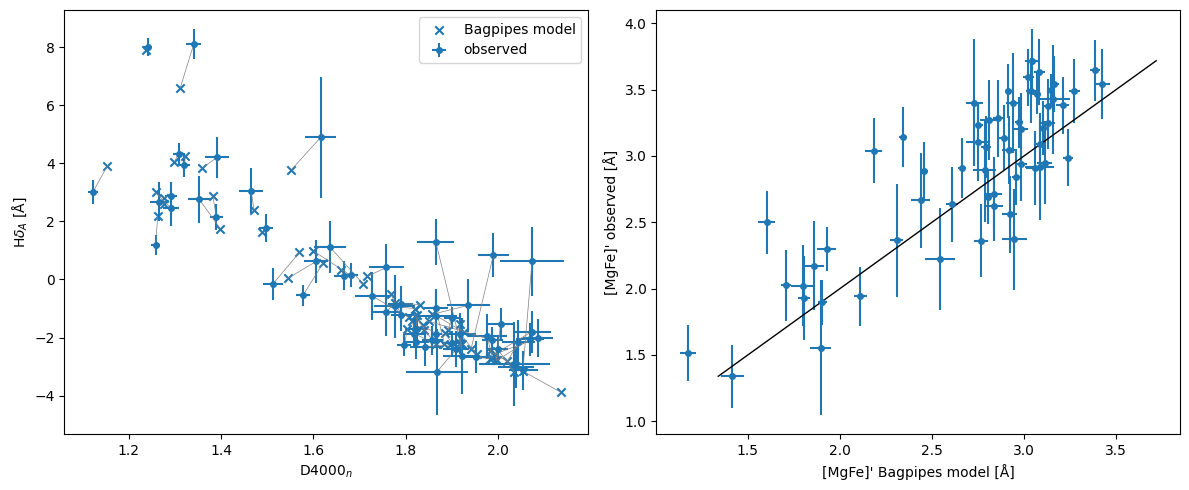

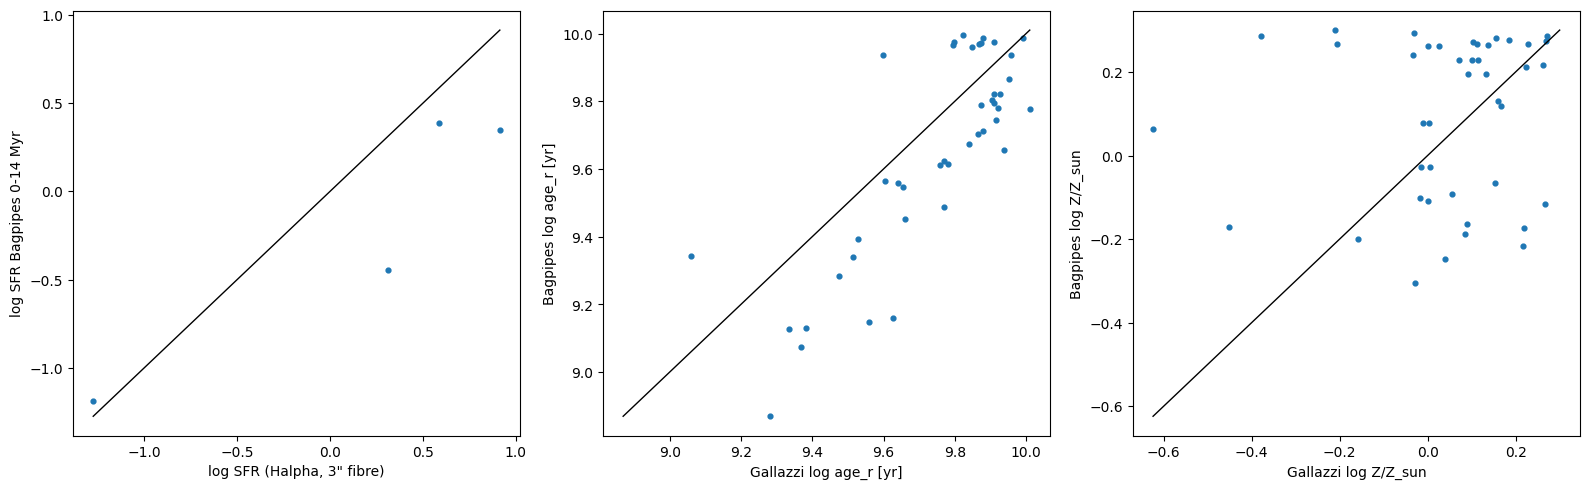

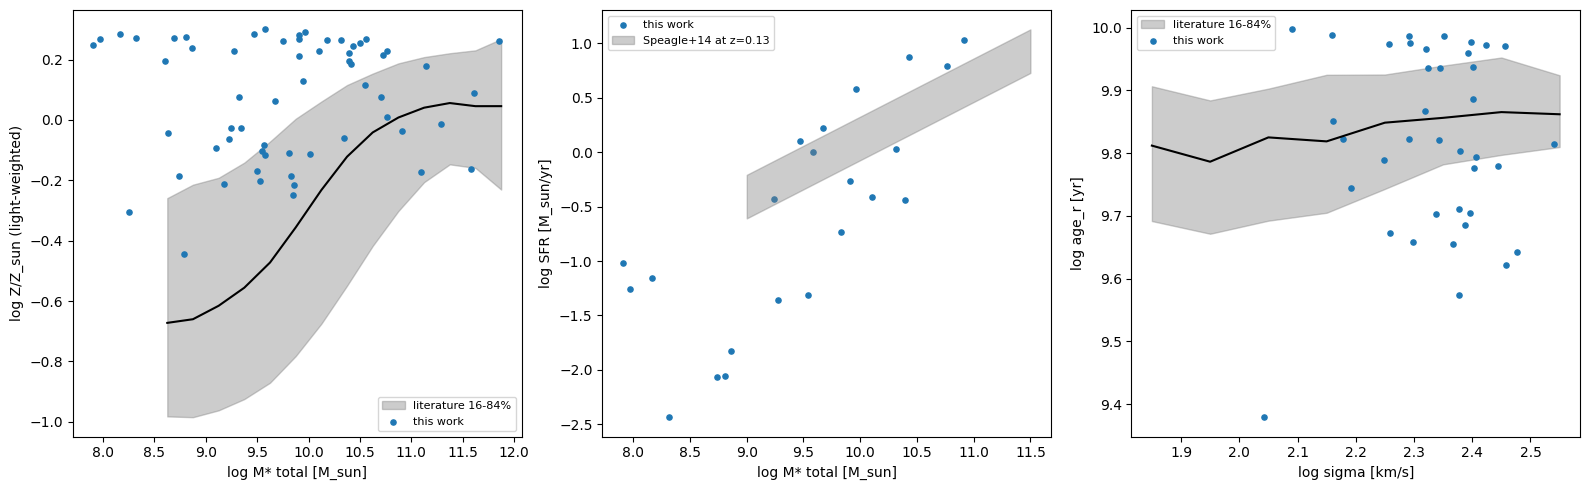

In [14]:
GROUPS = {
    "all": reference["fit_status"].eq("fitted"),
    "star-forming": star_forming,
    "passive": passive,
    "SDSS 3\"": reference["fiber_diameter"].eq(3.0),
    "BOSS 2\"": reference["fiber_diameter"].eq(2.0),
}
summary_rows = []
for group_name, in_group in GROUPS.items():
    group = reference[in_group]
    for name in sv.INDEX_NAMES:
        z_values = group[f"{name}_z"].dropna()
        summary_rows.append({"layer": "1 indices", "quantity": name, "group": group_name, "n": len(z_values),
                             "available": len(z_values) > 0,
                             "fraction_abs_z_below_2": np.mean(np.abs(z_values) < sv.MAX_Z_SCORE) if len(z_values) else np.nan,
                             "median_z": z_values.median() if len(z_values) else np.nan,
                             "z_scatter": 1.4826 * (z_values - z_values.median()).abs().median() if len(z_values) else np.nan})
    tracer_columns = {"Halpha SFR": group.loc[halpha_usable[in_group], "delta_log_sfr_halpha"],
                      "Gallazzi age": group["delta_log_age_gallazzi"], "Gallazzi metallicity": group["delta_log_z_gallazzi"]}
    for quantity, offsets in tracer_columns.items():
        offsets = offsets.dropna()
        summary_rows.append({"layer": "2 tracers", "quantity": quantity, "group": group_name, "n": len(offsets),
                             "available": len(offsets) > 0,
                             "median_offset": offsets.median() if len(offsets) else np.nan,
                             "scatter": 1.4826 * (offsets - offsets.median()).abs().median() if len(offsets) else np.nan})
    for quantity, column in (("mass-metallicity", "in_mass_metallicity_band"),
                             ("main sequence", "in_main_sequence_band"), ("age-sigma", "in_age_sigma_band")):
        flags = group[column].dropna()
        summary_rows.append({"layer": "3 relations", "quantity": quantity, "group": group_name, "n": len(flags),
                             "available": len(flags) > 0,
                             "fraction_inside_band": flags.astype(bool).mean() if len(flags) else np.nan})
validation_summary = pd.DataFrame(summary_rows)
validation_summary.to_csv(VALIDATION_SUMMARY_FILE, index=False)
display(validation_summary[validation_summary["group"] == "all"].round(3))

# Figure 1: indices, observed against posterior-predictive model
figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].errorbar(reference["D4000_n_obs"], reference["Hdelta_A_obs"], xerr=reference["D4000_n_obs_err"],
                 yerr=reference["Hdelta_A_obs_err"], fmt="o", ms=4, label="observed")
axes[0].scatter(reference["D4000_n_model_median"], reference["Hdelta_A_model_median"], marker="x", label="Bagpipes model")
for galaxy in reference.itertuples():
    axes[0].plot([galaxy.D4000_n_obs, galaxy.D4000_n_model_median], [galaxy.Hdelta_A_obs, galaxy.Hdelta_A_model_median],
                 color="grey", lw=0.5)
axes[0].set(xlabel="D4000$_n$", ylabel=r"H$\delta_A$ [Å]")
axes[0].legend()
axes[1].errorbar(reference["MgFe_prime_model_median"], reference["MgFe_prime_obs"], yerr=reference["MgFe_prime_obs_err"],
                 xerr=reference["MgFe_prime_model_std"], fmt="o", ms=4)
limits = [np.nanmin(reference["MgFe_prime_obs"]), np.nanmax(reference["MgFe_prime_obs"])]
axes[1].plot(limits, limits, color="black", lw=1)
axes[1].set(xlabel="[MgFe]' Bagpipes model [Å]", ylabel="[MgFe]' observed [Å]")
figure.tight_layout()
figure.savefig(INDEX_FIGURE_FILE, dpi=200)
plt.show()

# Figure 2: Halpha SFR and Gallazzi light-weighted age and metallicity
figure, axes = plt.subplots(1, 3, figsize=(16, 5))
comparisons = [
    (reference.loc[halpha_usable, "mpa_sfr_fib_p50"],
     reference.loc[halpha_usable, "bagpipes_log_sfr_young"], "log SFR (Halpha, 3\" fibre)", "log SFR Bagpipes 0-14 Myr"),
    (reference["gallazzi_log_age_p50"], reference["log_age_light_median"], "Gallazzi log age_r [yr]", "Bagpipes log age_r [yr]"),
    (reference["gallazzi_log_z_p50"], reference["log_metallicity_light_median"], "Gallazzi log Z/Z_sun", "Bagpipes log Z/Z_sun"),
]
for axis, (literature_values, bagpipes_values, x_label, y_label) in zip(axes, comparisons):
    axis.scatter(literature_values, bagpipes_values, s=12)
    finite = np.isfinite(literature_values) & np.isfinite(bagpipes_values)
    if finite.any():
        limits = [min(literature_values[finite].min(), bagpipes_values[finite].min()),
                  max(literature_values[finite].max(), bagpipes_values[finite].max())]
        axis.plot(limits, limits, color="black", lw=1)
    else:
        axis.text(0.5, 0.5, "not available", transform=axis.transAxes, ha="center")
    axis.set(xlabel=x_label, ylabel=y_label)
figure.tight_layout()
figure.savefig(TRACER_FIGURE_FILE, dpi=200)
plt.show()

# Figure 3: scaling relations with their 16-84th bands
figure, axes = plt.subplots(1, 3, figsize=(16, 5))
panels = [(mass_metallicity_band, reference["log_mstar_total"], reference["log_metallicity_light_median"],
           "log M* total [M_sun]", "log Z/Z_sun (light-weighted)"),
          (None, reference.loc[star_forming, "log_mstar_total"], reference.loc[star_forming, "log_sfr_total"],
           "log M* total [M_sun]", "log SFR [M_sun/yr]"),
          (age_sigma_band, pd.Series(log_sigma)[passive.to_numpy()], reference.loc[passive, "log_age_light_median"],
           "log sigma [km/s]", "log age_r [yr]")]
for axis, (band, x_values, y_values, x_label, y_label) in zip(axes, panels):
    if band is not None and len(band):
        centres = (band["x_low"] + band["x_high"]) / 2
        axis.fill_between(centres, band["y_p16"], band["y_p84"], color="grey", alpha=0.4, label="literature 16-84%")
        axis.plot(centres, band["y_median"], color="black")
    axis.scatter(x_values, y_values, s=14, label="this work")
    axis.set(xlabel=x_label, ylabel=y_label)
mass_grid = np.linspace(9, 11.5, 50)
median_redshift = reference.loc[star_forming, "z"].median()
axes[1].fill_between(mass_grid, sv.speagle_main_sequence(mass_grid, median_redshift) - sv.SPEAGLE_SCATTER,
                     sv.speagle_main_sequence(mass_grid, median_redshift) + sv.SPEAGLE_SCATTER, color="grey", alpha=0.4,
                     label=f"Speagle+14 at z={median_redshift:.2f}")
for axis in axes:
    axis.legend(fontsize=8)
figure.tight_layout()
figure.savefig(RELATION_FIGURE_FILE, dpi=200)
plt.show()

In [15]:
boss = reference["fiber_diameter"].eq(2.0)
assert reference.loc[boss, "mpa_sfr_fib_p50"].isna().all(), "BOSS spectra have no MPA-JHU row"
mpa_index_offset = (reference["D4000_n_obs"] - reference["mpa_d4000_n"]).median()
print(f"Index code check: median D4000_n difference to MPA-JHU = {mpa_index_offset:.3f}")
for label, ours, theirs in (("Hdelta_A", "Hdelta_A_obs", "mpa_lick_hd_a"), ("Mgb", "Mgb_obs", "mpa_lick_mgb"),
                            ("Fe5270", "Fe5270_obs", "mpa_lick_fe5270"), ("Fe5335", "Fe5335_obs", "mpa_lick_fe5335")):
    print(f"Index code check: median {label} difference to MPA-JHU = {(reference[ours] - reference[theirs]).median():.3f}")

Index code check: median D4000_n difference to MPA-JHU = -0.000
Index code check: median Hdelta_A difference to MPA-JHU = 0.001
Index code check: median Mgb difference to MPA-JHU = -0.009
Index code check: median Fe5270 difference to MPA-JHU = -0.011
Index code check: median Fe5335 difference to MPA-JHU = 0.018


In [16]:
# The calibration verdict of the fitter (section 5) is stored on every row; empty while the mocks are incomplete
reference["fitter_calibrated"] = fitter_calibrated

reference.to_csv(OUTPUT_FILE, index=False)
assert reference.loc[fitted, "mw_age_median"].notna().all(), "A fitted galaxy has no labels in the output"
print(f"{OUTPUT_FILE}: {len(reference)} galaxies, {fitted.sum()} fitted, "
      f"{reference['converged'].eq(True).sum()} converged, {reference['covered'].sum()} covered; "
      f"fitter_calibrated = {fitter_calibrated}")
display(reference["split"].value_counts())

spectroscopic_reference.csv: 60 galaxies, 60 fitted, 60 converged, 58 covered; fitter_calibrated = <NA>


split
validation    32
test          26
excluded       2
Name: count, dtype: int64

## Next pass
Raise `GALAXIES_PER_CELL` and re-run: the selection in `selection.csv` only grows (new picks are appended, every stored or fitted galaxy stays in the table), the new jobs are exported next to the old ones, and `run_spectral_fits.py` fits only the jobs without an `.h5` file. The stored calibration mocks (`MOCK_FILE`) are reused, so the calibration test stays valid, and the hash split never moves an existing galaxy. Delete `MOCK_FILE` and the `calib_*` fits to draw new mocks. Add DR4 Stripe 82 galaxies by pointing `SPLUS_FILE` at a DR4 catalogue with the same columns.